# First citywide LSTM forecasting experiment
An educational, exploratory experiment on the existing January–February 2024 citywide series. February's test window was already inspected for baselines, XGBoost and MLP; this is not an untouched final benchmark. The final January 2024–December 2025 plan is unchanged.

At each NYC-local midnight, the model receives the **previous 48 completed hourly counts** and predicts the **next 24 elapsed hourly counts** together. No future actuals or weather enter the input.

## Isolated environment
Select **CityPulse AI TensorFlow (Python 3.11)**. Stable TensorFlow has no Python 3.14 wheel, so the existing `.venv` is unchanged. We use `.venv-tensorflow-311`, created from the already installed ARM64 Python 3.11.15 in `anaconda3/envs/bookrag`. The first attempt with installed Python 3.11.4 hit a native readline crash during pytest startup; that environment is retained and unused.

Install from the project root with `.venv-tensorflow-311/bin/python -m pip install -e '.[tensorflow,notebooks,dev]'`. TensorFlow/Keras stay isolated from the existing PyTorch/XGBoost environment. We explicitly use CPU, one thread and a fixed seed. Restart the kernel before running all cells, since CPU thread configuration must precede TensorFlow device initialization.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from IPython.display import display, Markdown
from citypulse_ai.forecasting.lstm import configure_cpu, tensor_dataset
configure_cpu(seed=42)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__, '| CPU only')
from citypulse_ai.forecasting.experiment import load_development_citywide, START, END
from citypulse_ai.forecasting.baselines import LOCAL_ZONE, evaluate_midnights
from citypulse_ai.forecasting.xgboost_model import VALIDATION_START, TEST_START
from citypulse_ai.forecasting.lstm import prepare_sequences, run_lstm_experiment, forecast_next_day, build_model, LSTMForecaster
plt.rcParams.update({'figure.figsize': (12,4), 'axes.grid': True})

TensorFlow: 2.21.0 | Keras: 3.15.1 | CPU only


## Read-only data and eligibility before training
We reuse the existing loader with hash, duplicate and ride-count reconciliation checks. Inputs use UTC elapsed-hour grids, while issuance and split boundaries use America/New_York. January/February 2024 contain no DST transition.

January 1–2 cannot supply 48 hours of in-window history; they are explicitly excluded from training. We create exactly one sequence per eligible midnight. Internal missing observations raise errors. Validation/test past observations may become inputs only after those hours have completed.

In [2]:
citywide, provenance = load_development_citywide(ROOT / 'outputs/historical')
assert len(citywide) == 1440 and int(citywide.ride_count.sum()) == 4006382
assert provenance['missing_citywide_hours'] == 0
series = citywide.set_index('hour_start').ride_count.astype(float)
january = series.loc[series.index < VALIDATION_START]
train_sequences = prepare_sequences(january, START, VALIDATION_START, drop_initial_warmup=True)
validation_sequences = prepare_sequences(series, VALIDATION_START, TEST_START)
test_sequences = prepare_sequences(series, TEST_START, END)
assert [len(s.origins) for s in (train_sequences, validation_sequences, test_sequences)] == [29,14,15]
display(pd.DataFrame([{'split': name, 'sequences': len(s.origins), 'input_shape': s.inputs.shape,
                       'target_shape': s.targets.shape, 'first_origin': s.origins.min(),
                       'last_origin': s.origins.max(), 'dropped_warmup': s.dropped_warmup}
                      for name,s in [('train',train_sequences),('validation',validation_sequences),('test',test_sequences)]]))

,split,sequences,input_shape,target_shape,first_origin,last_origin,dropped_warmup
0,train,29,"(29, 48, 1)","(29, 24)",2024-01-03 05:00:00+00:00,2024-01-31 05:00:00+00:00,2
1,validation,14,"(14, 48, 1)","(14, 24)",2024-02-01 05:00:00+00:00,2024-02-14 05:00:00+00:00,0
2,test,15,"(15, 48, 1)","(15, 24)",2024-02-15 05:00:00+00:00,2024-02-29 05:00:00+00:00,0


## One small, bounded training run
A shared univariate StandardScaler fits the 744 January observations only, covering January training inputs and targets; it never sees February values. The same mean/scale transform history and targets. The network is **LSTM(32) → Dense(24)**: `(samples,48,1)` inputs → `(samples,24)` outputs. Parameter count is 4×32×(1+32+1) = 4,352 recurrent parameters plus 32×24+24 = 792 Dense parameters: **5,144 total**.

Adam learning rate 0.001, batch size 4, seed 42, at most 80 epochs, patience 10, validation scaled MSE. The LSTM is stateless across samples; shuffling January sequences does not transfer state or mix splits. Validation chooses weights but never contributes gradients. The saved absolute-best validation checkpoint is restored before evaluation. No test-driven tuning or February refit.

After training, Keras summary also lists Adam optimizer-state variables. The network itself has 5,144 learned parameters; optimizer bookkeeping does not add extra model weights.

In [3]:
result_dir = ROOT / 'outputs/phase3-tensorflow-lstm-jan-feb-2024' / datetime.now(timezone.utc).strftime('run-%Y%m%dT%H%M%S%fZ')
result, predictions, lstm_metrics = run_lstm_experiment(series, result_dir/'best.weights.h5')
result.forecaster.model.summary()
print('Epochs run:', len(result.history), '| selected epoch:', result.best_epoch, '| fit/restore/evaluation seconds:', result.duration_seconds)
print('Restored-model training scaled MSE:', result.train_mse_scaled)
print('Restored-model validation scaled MSE:', result.validation_mse_scaled)

/Users/sanjeevani1109/Desktop/Masters/Projects/CityPulse-AI/.venv-tensorflow-311/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Model: "citywide_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,434 (60.29 KB)

 Trainable params: 5,144 (20.09 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,290 (40.20 KB)

Epochs run: 30 | selected epoch: 20 | fit/restore/evaluation seconds: 3.474781625031028
Restored-model training scaled MSE: 0.3430977165699005
Restored-model validation scaled MSE: 0.4303082525730133


## Learning curves and interpretation
Keras training loss averages batch losses while weights change through each epoch. Validation loss evaluates the completed epoch state, so those curves are not identical measurement procedures. The restored-model losses printed above evaluate both datasets with frozen best weights.

If training improves while validation worsens, that is evidence of overfitting on this split. If both losses remain high, the model may underfit or lack useful inputs. We do not change hyperparameters after inspecting test results.

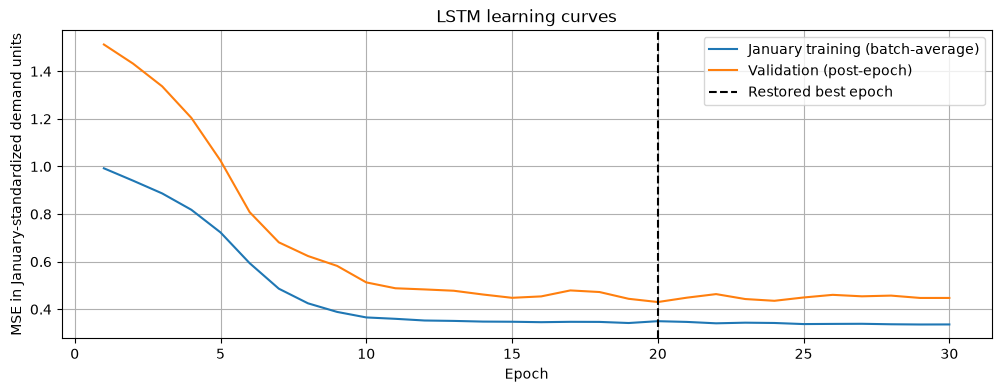

In [4]:
fig, ax = plt.subplots()
ax.plot(result.history.epoch, result.history.train_mse_scaled, label='January training (batch-average)')
ax.plot(result.history.epoch, result.history.validation_mse_scaled, label='Validation (post-epoch)')
ax.axvline(result.best_epoch, color='black', linestyle='--', label='Restored best epoch')
ax.set(xlabel='Epoch', ylabel='MSE in January-standardized demand units', title='LSTM learning curves')
ax.legend(); plt.show()

## Compare with the four previous models
Metrics use inverse-transformed, nonnegative predictions in **rides/hour**. WAPE is pooled absolute error divided by actual demand, expressed as a percentage. We calculate the existing seasonal baselines and load prior XGBoost/MLP measured results with matching source-manifest provenance; neither trained comparator is rerun or modified.

Unlike the prior models, this LSTM has only 48 hours of univariate input, without calendar features or lag 168. Lower errors would be a measured exploratory improvement, not evidence that recurrent models are universally superior.

In [5]:
xgb_record = json.loads((ROOT/'outputs/phase3-xgboost-jan-feb-2024/experiment.json').read_text())
mlp_record_path = sorted((ROOT/'outputs/phase3-pytorch-mlp-jan-feb-2024').glob('*/experiment.json'))[-1]
mlp_record = json.loads(mlp_record_path.read_text())
for old in (xgb_record, mlp_record):
    assert old['provenance']['manifest_sha256'] == provenance['manifest_sha256']
comparators = [r for r in xgb_record['metrics'] if r['model']=='XGBoost'] + [r for r in mlp_record['metrics'] if r['model']=='PyTorch MLP']
baseline_tables=[]
for split,left,right in [('validation',VALIDATION_START,TEST_START),('test',TEST_START,END)]:
    _, scores = evaluate_midnights(series,left,right)
    baseline_tables.append(scores.assign(split=split,model=scores.lag_hours.map({24:'Lag 24',168:'Lag 168'})))
comparison = pd.concat([*baseline_tables,pd.DataFrame(comparators),lstm_metrics],ignore_index=True)
comparison=comparison[['split','model','forecast_origins','target_hours','MAE','RMSE','WAPE_percent']]
display(comparison.round(3))
for split in ['validation','test']:
    scores=comparison[comparison.split.eq(split)].set_index('model')
    outcomes=', '.join(f"{name}: {'lower' if scores.loc['Keras LSTM','MAE']<scores.loc[name,'MAE'] else 'higher or equal'} MAE"
                      for name in ['Lag 24','Lag 168','XGBoost','PyTorch MLP'])
    display(Markdown(f"**{split.title()} LSTM MAE {scores.loc['Keras LSTM','MAE']:.2f}**; compared with {outcomes}."))

,split,model,forecast_origins,target_hours,MAE,RMSE,WAPE_percent
0,validation,Lag 24,14,336,908.146,1454.002,27.897
1,validation,Lag 168,14,336,715.628,1202.430,21.983
2,test,Lag 24,15,360,759.853,1199.061,26.666
3,test,Lag 168,15,360,948.014,1438.950,33.269
4,validation,XGBoost,14,336,782.443,1242.431,24.035
5,test,XGBoost,15,360,649.272,994.204,22.785
6,validation,PyTorch MLP,14,336,782.260,1160.315,24.030
7,test,PyTorch MLP,15,360,622.371,973.487,21.841
8,validation,Keras LSTM,14,336,965.194,1341.215,29.649
9,test,Keras LSTM,15,360,680.162,1011.211,23.869


**Validation LSTM MAE 965.19**; compared with Lag 24: higher or equal MAE, Lag 168: higher or equal MAE, XGBoost: higher or equal MAE, PyTorch MLP: higher or equal MAE.

**Test LSTM MAE 680.16**; compared with Lag 24: lower MAE, Lag 168: lower MAE, XGBoost: higher or equal MAE, PyTorch MLP: higher or equal MAE.

## Actual versus predicted demand
The plot shows the final test week, including leap day. Each day is a forecast block issued at local midnight using the restored January-trained model. Look for peak misses and systematic demand-shape errors.

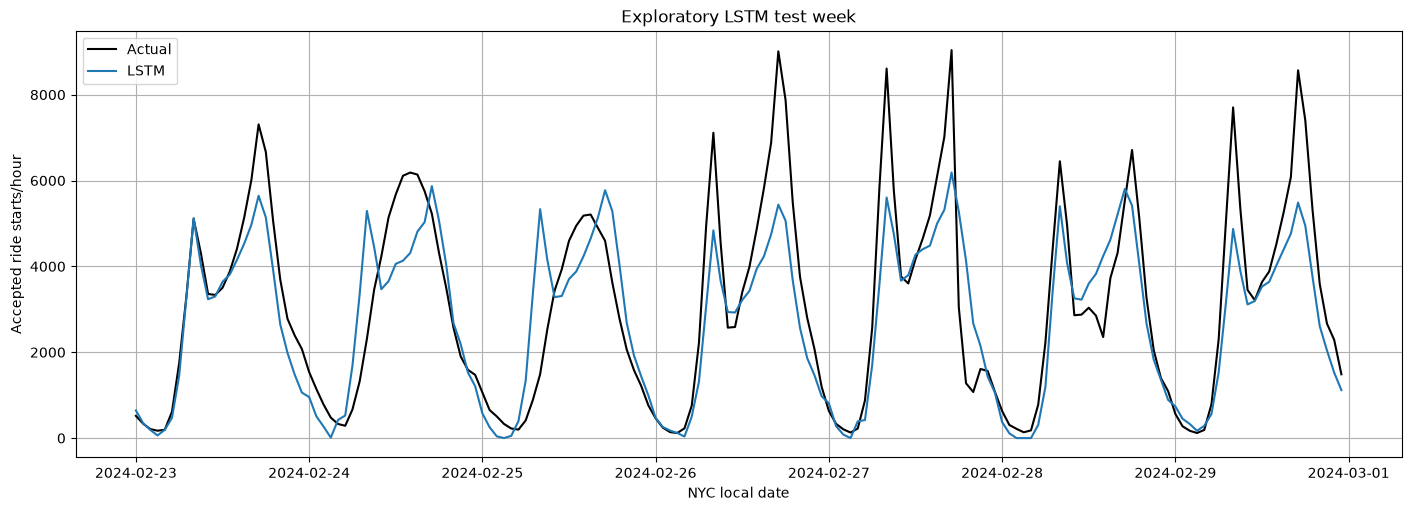

In [6]:
week=predictions[predictions.split.eq('test') & predictions.hour_start.ge(pd.Timestamp('2024-02-23',tz=LOCAL_ZONE))]
fig,ax=plt.subplots(figsize=(14,5),constrained_layout=True)
local_hours=week.hour_start.dt.tz_convert(LOCAL_ZONE)
ax.plot(local_hours,week.actual,color='black',label='Actual')
ax.plot(local_hours,week.prediction,label='LSTM')
ax.set(xlabel='NYC local date',ylabel='Accepted ride starts/hour',title='Exploratory LSTM test week')
ax.legend();plt.show()

## Restore the checkpoint and issue a next-day example
Weights must reproduce the evaluated forecast when reloaded with the saved January scaler. We issue March 1 at midnight using February 28–29 observations; no March target is loaded or scored. The output contains exactly 24 elapsed hours.

/Users/sanjeevani1109/Desktop/Masters/Projects/CityPulse-AI/.venv-tensorflow-311/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_1', because it has 2 variables whereas the saved optimizer has 12 variables. 
  saveable.load_own_variables(store)


,hour_start,prediction,NYC_target_hour
0,2024-03-01 05:00:00+00:00,829.103149,2024-03-01 00:00:00-05:00
1,2024-03-01 06:00:00+00:00,349.013672,2024-03-01 01:00:00-05:00
2,2024-03-01 07:00:00+00:00,102.104492,2024-03-01 02:00:00-05:00
3,2024-03-01 08:00:00+00:00,0.000000,2024-03-01 03:00:00-05:00
4,2024-03-01 09:00:00+00:00,354.766602,2024-03-01 04:00:00-05:00
5,2024-03-01 10:00:00+00:00,443.757568,2024-03-01 05:00:00-05:00
6,2024-03-01 11:00:00+00:00,1652.688721,2024-03-01 06:00:00-05:00
7,2024-03-01 12:00:00+00:00,3514.911377,2024-03-01 07:00:00-05:00
8,2024-03-01 13:00:00+00:00,5536.449219,2024-03-01 08:00:00-05:00
9,2024-03-01 14:00:00+00:00,4622.274414,2024-03-01 09:00:00-05:00


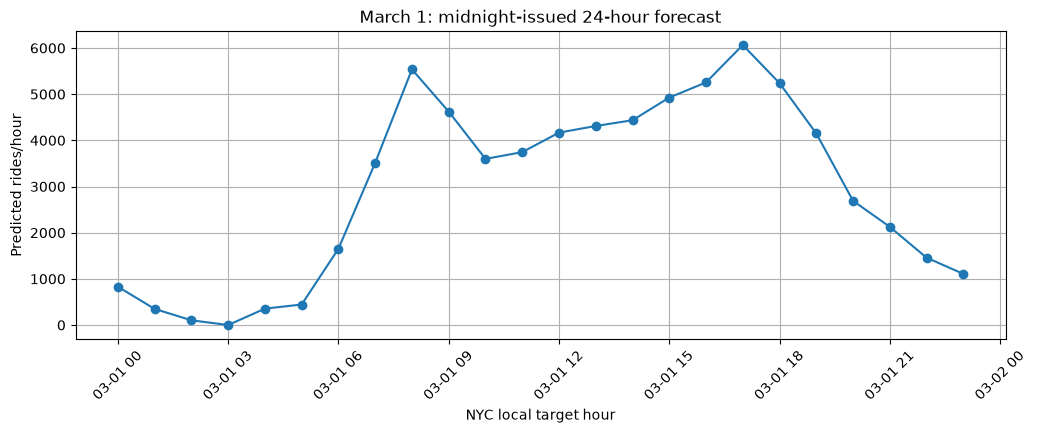

In [7]:
restored_model=build_model(seed=42)
restored_model.load_weights(result.checkpoint_path)
restored=LSTMForecaster(restored_model,result.forecaster.scaler)
example=forecast_next_day(restored,series.loc[series.index<END],END)
original_example=forecast_next_day(result.forecaster,series.loc[series.index<END],END)
np.testing.assert_array_equal(example.prediction,original_example.prediction)
example_table=example[['hour_start','prediction']].copy()
example_table['NYC_target_hour']=example_table.hour_start.dt.tz_convert(LOCAL_ZONE)
display(example_table)
fig,ax=plt.subplots()
ax.plot(example_table.NYC_target_hour,example_table.prediction,marker='o')
ax.set(xlabel='NYC local target hour',ylabel='Predicted rides/hour',title='March 1: midnight-issued 24-hour forecast')
plt.xticks(rotation=45);plt.show()

## Limits and measured conclusions
There are only 29 training sequences for 5,144 parameters. The inputs cannot explicitly encode last-week demand or calendar effects. Training targets differ in warm-up from the MLP/XGBoost experiments, while validation/test targets and issuance rules match. Small winter-only data, correlated errors and omitted weather/holiday information limit interpretation.

The test period has been inspected previously. No statistical-significance or final 24-month model claim is made. All results are exploratory, and no test-driven retuning is performed.

**Measured outcome:** the fit stopped after 30 epochs and restored epoch 20. Frozen-state training/validation scaled MSE were 0.343098 / 0.430308. Validation MAE 965.19 is worse than all four comparators. Test MAE 680.16 beats lag 24 (759.85) and lag 168 (948.01), but loses to XGBoost (649.27) and PyTorch MLP (622.37). The test plot misses several commute peaks. These measured results do not justify a claim that LSTM outperforms the existing trained models.

In [8]:
record={'exploratory_development_experiment':True,'test_previously_inspected':True,
        'versions':{'tensorflow':tf.__version__,'keras':keras.__version__,'numpy':np.__version__,'pandas':pd.__version__},
        'provenance':provenance,'settings':result.settings,'parameters':result.forecaster.model.count_params(),
        'training_sequences':result.training_sequences,'validation_sequences':result.validation_sequences,
        'test_sequences':len(test_sequences.origins),'dropped_warmup_sequences':result.dropped_warmup,
        'epochs_run':len(result.history),'best_epoch':result.best_epoch,
        'training_duration_seconds':result.duration_seconds,'train_mse_scaled':result.train_mse_scaled,
        'validation_mse_scaled':result.validation_mse_scaled,'scaler_mean':result.forecaster.scaler.mean_.tolist(),
        'scaler_scale':result.forecaster.scaler.scale_.tolist(),'scaler_variance':result.forecaster.scaler.var_.tolist(),
        'scaler_training_hours':int(result.forecaster.scaler.n_samples_seen_),
        'checkpoint_relative_path':str(result.checkpoint_path.relative_to(ROOT)),
        'prior_mlp_record':str(mlp_record_path.relative_to(ROOT)),
        'metrics':comparison.to_dict(orient='records'),
        'example_forecast':example_table.assign(hour_start=example_table.hour_start.astype(str),
                 NYC_target_hour=example_table.NYC_target_hour.astype(str)).to_dict(orient='records')}
(result_dir/'experiment.json').write_text(json.dumps(record,indent=2,default=str)+'\n')
result.history.to_csv(result_dir/'loss_history.csv',index=False)
print('Measured outputs:',result_dir.relative_to(ROOT))

Measured outputs: outputs/phase3-tensorflow-lstm-jan-feb-2024/run-20261012T141848308777Z
